This is the cutdown companion Jupyter Notebook of Chapter 9, Beyond Born Oppenheimer, of the second edition of the book titled: "Quantum Chemistry and Computing for the Curious: Illustrated with Python and Qiskit® code" and with ISBN-13: 978-1803243900. Copyright © 2026, Keeper L. Sharkey and Alain Chancé.

The following MIT license only applies to the code, and not to the text and images. The authors are not granting a license to replicate or reuse the text and images in the companion Jupyter notebook.

# MIT License

Copyright (c) 2026 Packt

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

# 9. Beyond Born-Oppenheimer

# Technical requirements
A companion Jupyter notebook for this chapter can be downloaded from GitHub at  https://github.com/PacktPublishing/Quantum-Chemistry-and-Computing-for-the-Curious-Second-Edition. For more information about how to install Qiskit, please refer to the IBM Install Qiskit documentation, https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit, and in Robert Loredo's book [Loredo_Qiskit].

The companion Jupyter notebook automatically installs the following list of libraries:
-	NumPy [NumPy], an open-source Python library that is used in almost every field of science and engineering
-	SciPy [SciPy], a free and open-source Python library used for scientific computing and technical computing

The companion Jupyter notebook does not include the installation of the Psi4 free and open source software for high-throughput quantum chemistry [Psi4_0], which we used to perform a simple calculation of the vibrational frequency analysis of the carbon dioxide ($\text{CO}_{2}$) molecule. We refer the reader interested in installing this package to the “Get Started with Psi4” [Psi4_1] documentation and to the article Ref. [Psi4_3].

## Installing NumPy, SciPy and math modules

In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [5]:
from scipy.special import hermite, factorial

# 9.1. Non-Born-Oppenheimer molecular Hamiltonian
## Internal Hamiltonian operator

### Explicitly correlated all-particle Gaussian functions
## Energy minimization

# 9.2. Vibrational frequency analysis calculations
## Modeling the vibrational-rotational levels of a diatomic molecule

In [6]:
def N(v):
  return 1./np.sqrt(np.sqrt(np.pi)*2**v*factorial(v))

In [7]:
# Normalized harmonic-oscillator wavefunction
def psi(v, x):
    H = hermite(v)
    norm = 1.0 / np.sqrt(2**v * factorial(v) * np.sqrt(np.pi))
    return norm * np.exp(-x**2/2) * H(x)

In [8]:
def plot(n):
    fig, ax = plt.subplots(figsize=(n+1, n+1))

    # x-range wide enough for all states
    xmax = np.sqrt(2*n + 1) * 1.2
    x = np.linspace(-xmax, xmax, 2000)

    # Potential curve
    V = 0.5 * x**2
    ax.plot(x, V, color='black', linewidth=2, label='V(x)')

    # Wavefunction scaling factor so curves fit nicely
    scale = 0.5  # adjust to taste

    for v in range(n):
        E = v + 0.5

        # Normalized probability density
        P = psi(v, x)**2

        # Shifted and scaled curve
        ax.plot(x, scale*P + E, linewidth=1.5)

        # Energy level line
        ax.axhline(E, color='gray', linestyle='--', linewidth=1)

        # Label
        ax.text(xmax*0.92, E + 0.05, f"$v={v}$", fontsize=12)

    ax.set_xlabel("x", fontsize=14)
    ax.set_ylabel(r"$|\psi_v(x)|^2$", fontsize=14)
    ax.set_xlim(-xmax, xmax)
    ax.set_ylim(-0.2, n + 1)
    ax.set_title("Harmonic Oscillator: Potential and Vibrational States", fontsize=16)

    plt.show()

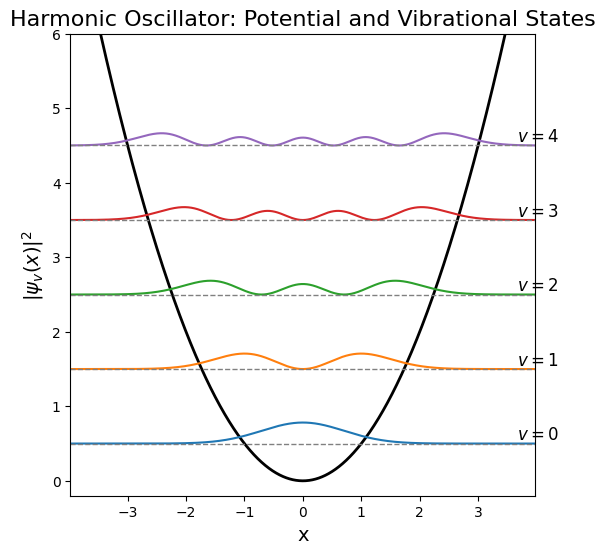

In [9]:
plot(5)

In [10]:
def Frot(J, Be, De, He, show=False):
  F = Be*J*(J+1) + De*J**2*(J+1)**2 - He*J*3*(J+1)**3*10e-5
  if show:
    print("{} {:.2f}".format(J, F))
  return F

In [11]:
# Source of the ground rotational state E(v,J=0) energy: [Komasa]
# Source of the constants data Ee, Be, De, He, and rms: [Campargue]

#      v   E(v,J=0)    Ee          Be         De        He     rms
rov = {0: (36118.0696, 0.0,        59.33289, -0.045498, 4.277, 3.4), 
       1: (31956.9034, 4161.1693,  56.37318, -0.043961, 4.168, 3.2),
       2: (28031.0670, 8087.0058,  53.47892, -0.042523, 4.070, 3.2),
       3: (24335.6787, 11782.3940, 50.62885, -0.041175, 3.963, 3.2),
       4: (20867.7039, 15250.3688, 47.79997, -0.039927, 3.846, 3.2),
       5: (17626.1400, 18491.9328, 44.96596, -0.038795, 3.717, 3.2),
       6: (14612.2901, 21505.7826, 42.09566, -0.037808, 3.571, 3.1),
       7: (11830.1543, 24287.9184, 39.15105, -0.037004, 3.399, 3.1),
       8: (9286.9790,  26831.0937, 36.08416, -0.036451, 3.187, 3.1),
       9: (6994.0292,  29124.0436, 32.83233, -0.036251, 2.902, 3.2)}

In [12]:
print("v  E(v,J=0)    E(v,J=1)    BO Diff.")
for v in range(10):
    E0 = rov[v][0] - Frot(0, rov[v][2], rov[v][3], rov[v][4])
    E1 = rov[v][0] - Frot(1, rov[v][2], rov[v][3], rov[v][4])
    print("{}  {:.4f}  {:.4f}  {:.4f}".format(v, E0, E1, E0 - E1))

v  E(v,J=0)    E(v,J=1)    BO Diff.
0  36118.0696  35999.5961  118.4735
1  31956.9034  31844.3429  112.5605
2  28031.0670  27924.2890  106.7780
3  24335.6787  24234.5952  101.0835
4  20867.7039  20772.2729  95.4310
5  17626.1400  17536.3722  89.7678
6  14612.2901  14528.2586  84.0315
7  11830.1543  11752.0084  78.1459
8  9286.9790  9214.9641  72.0149
9  6994.0292  6928.5165  65.5127


## Computing all vibrational-rotational levels of a molecule
### Optimizing the geometry of the molecule
### Calculating a force constant Hessian matrix
### Converting to mass weighted Cartesian coordinates
### Diagonalizing the mass weighted Hessian matrix

In [13]:
do_Psi4 = True
try:
    import psi4
except Exception as e:
    do_Psi4 = False

if do_Psi4:
    # We redirect the output of the Psi4 calculation to a file:
    psi4.core.set_output_file('psi_CO2_output.txt', False)

    # We specify the amount of memory for the calculation:
    psi4.set_memory('500 MB')

    # Then we define the geometry of the CO2 molecule [Psi4_2]:
    co2 = psi4.geometry(
        """
        symmetry c1
        0 1
        C 1.6830180 -0.4403696 3.1117942
        O 0.5425545 -0.2216001 2.9779653
        O 2.8186228 -0.6587208 3.2810031
        units angstrom
        """)

    # Print the energy
    psi4.energy('scf/cc-pvdz')

    # We optimize the geometry of the molecule:
    psi4.set_options({'reference': 'rhf'})
    psi4.optimize('scf/cc-pvdz', molecule=co2)

    # We now perform a vibrational frequency analysis:
    scf_e, scf_wfn = psi4.frequency('scf/cc-pvdz', molecule=co2, return_wfn=True)

    # We print the frequencies with the following code:
    for i in range(4):
        print(scf_wfn.frequencies().get(0,i))

else:
    print("Here is the result, a list of harmonic vibrational frequencies in cm-1:")
    print("761.4181081677268 \n761.4181227549785 \n1513.1081106509557 \n2579.8280005025586")

Here is the result, a list of harmonic vibrational frequencies in cm-1:
761.4181081677268 
761.4181227549785 
1513.1081106509557 
2579.8280005025586


# 9.3. Vibrational spectra for ortho-para isomerization of hydrogen molecules

# Summary

# Questions

In [14]:
#@title Enter your answer True, False or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "True"
if answer == solution:
  print("Correct")
elif answer == '?':
  print(solution)
else:
  print("Incorrect, please try again")

Incorrect, please try again


In [15]:
#@title Enter your answer as a string of characters or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "2.	Explicitly correlated Gaussian function"
if answer == solution:
  print("Correct")
elif answer == '?':
  print(solution)
else:
  print("Incorrect, please try again")

Incorrect, please try again


In [16]:
#@title Enter your answer True, False or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "True"
if answer == solution:
  print("Correct")
elif answer == '?':
  print(solution)
else:
  print("Incorrect, please try again")

Incorrect, please try again


In [17]:
#@title Enter your answer True, False or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "True"
if answer == solution:
  print("Correct")
elif answer == '?':
  print(solution)
else:
  print("Incorrect, please try again")

Incorrect, please try again


In [18]:
#@title Enter your answer True, False or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "True"
if answer == solution:
  print("Correct")
elif answer == '?':
  print(solution)
else:
  print("Incorrect, please try again")

Incorrect, please try again


# References
[Loredo_Qiskit] Robert Loredo, Chapter 3: Introducing and Installing Qiskit. Learn Quantum Computing with Python and IBM Quantum, Packt Publishing, 2025. ISBN 978-1803244808, https://www.amazon.fr/Learn-Quantum-Computing-Python-IBM/dp/1803244801/

[NumPy] NumPy: the absolute basics for beginners, https://numpy.org/doc/stable/user/absolute_beginners.html

[Psi4_0] Psi4 manual master index, https://psicode.org/psi4manual/master/index.html 

[Psi4_1] Get Started with PSI4, https://psicode.org/installs/v110zero/ 

[Psi4_2] Test case for Binding Energy of C4H5N (Pyrrole) with CO2 using MP2/def2-TZVPP, https://github.com/psi4/psi4/blob/master/samples/mp2-def2/input.dat 

[Psi4_3] Smith DGA, Burns LA, Simmonett AC, Parrish RM, Schieber MC, Galvelis R, Kraus P, Kruse H, Di Remigio R, Alenaizan A, James AM, Lehtola S, Misiewicz JP, Scheurer M, Shaw RA, Schriber JB, Xie Y, Glick ZL, Sirianni DA, O'Brien JS, Waldrop JM, Kumar A, Hohenstein EG, Pritchard BP, Brooks BR, Schaefer HF 3rd, Sokolov AY, Patkowski K, DePrince AE 3rd, Bozkaya U, King RA, Evangelista FA, Turney JM, Crawford TD, Sherrill CD, Psi4 1.4: Open-source software for high-throughput quantum chemistry, J Chem Phys. 2020 May 14;152(18):184108. doi: 10.1063/5.0006002. PMID: 32414239; PMCID: PMC7228781, https://www.ncbi.nlm.nih.gov/pmc/articles/PMC7228781/pdf/JCPSA6-000152-184108_1.pdf 

[SciPy] Statistical functions (scipy.stats), https://projects.scipy.org/getting-started.html

## Python

In [21]:
# Display Python version
!python --version

Python 3.13.11


## Psi4

In [22]:
if do_Psi4:
    import psi4
    print(psi4.__version__)